In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from sklearn import datasets

In [2]:
iris = datasets.load_iris()
X = iris.data
target = iris.target
Y = to_categorical(target).astype("uint8")
# 0 => [1 0 0]
# 1 => [0 1 0]
# 2 => [0 0 1]

In [3]:
idx = 0
print(X[idx])
print(target[idx])
print(Y[idx])

[5.1 3.5 1.4 0.2]
0
[1 0 0]


# 1. Red Original: 4 x 3 x 3 (Sigmoide + MSE)
Topología inicial con una sola capa oculta de 3 neuronas y capa de salida de 3 neuronas con activación sigmoide.

In [4]:
model_orig = keras.Sequential([
    layers.Dense(3, activation="sigmoid", name="layer1", input_shape=(4,)),
    layers.Dense(3, activation="sigmoid", name="layer2")
], name="sequential_original")
model_orig.summary()

Model: "sequential_original"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 layer1 (Dense)              (None, 3)                 15        
 layer2 (Dense)              (None, 3)                 12        
Total params: 27 (108.00 Byte)
Trainable params: 27 (108.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


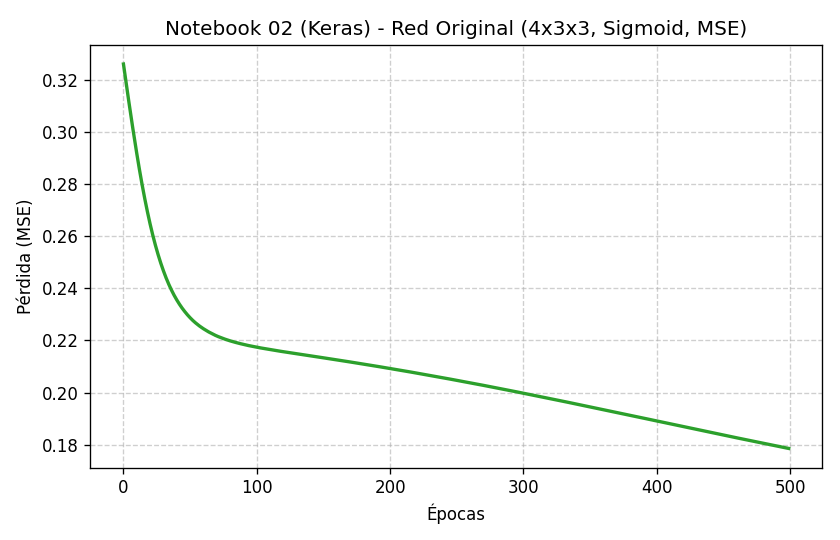

Época 500/500 - Pérdida (MSE) final: 0.1786


In [5]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.03)
loss = tf.keras.losses.MeanSquaredError()
model_orig.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])
history_orig = model_orig.fit(X, Y, epochs=500, verbose=0)

plt.figure(figsize=(7, 4.5))
plt.plot(history_orig.history['loss'], color='#2ca02c', lw=2)
plt.title('Notebook 02 (Keras) - Red Original (4x3x3, Sigmoide, MSE)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (MSE)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Red Profunda: 4 x 3 x 3 x 3 x 3 (Cuatro capas con Sigmoide + MSE)
Incorporamos dos capas ocultas intermedias (4 capas densas en total), manteniendo la función de activación sigmoide, optimizador SGD con $\eta=0.03$ y 500 épocas.

In [6]:
model_deep = keras.Sequential([
    layers.Dense(3, activation="sigmoid", name="layer1", input_shape=(4,)),
    layers.Dense(3, activation="sigmoid", name="layer2"),
    layers.Dense(3, activation="sigmoid", name="layer3"),
    layers.Dense(3, activation="sigmoid", name="layer4")
], name="sequential_profunda")
model_deep.summary()

Model: "sequential_profunda"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 layer1 (Dense)              (None, 3)                 15        
 layer2 (Dense)              (None, 3)                 12        
 layer3 (Dense)              (None, 3)                 12        
 layer4 (Dense)              (None, 3)                 12        
Total params: 51 (204.00 Byte)
Trainable params: 51 (204.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


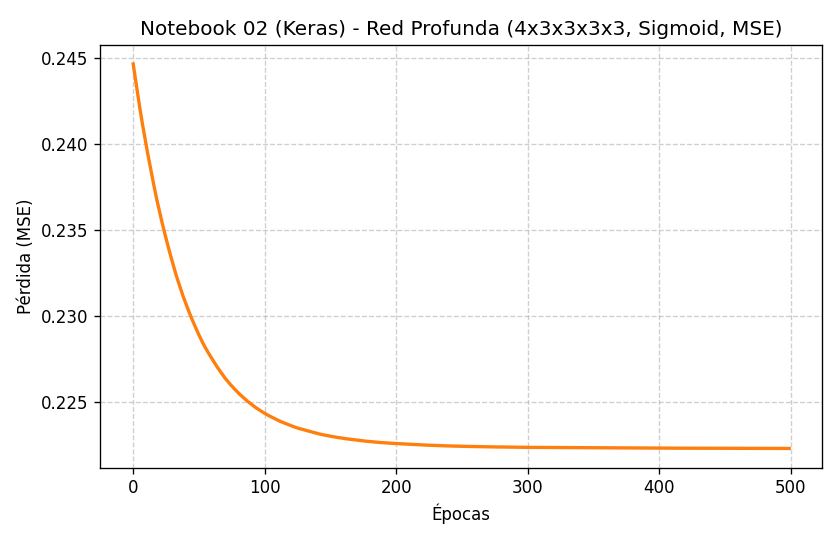

Época 500/500 - Pérdida (MSE) final: 0.2223
Observación: La pérdida final es mayor que la de la red original de 2 capas (0.2223 vs 0.1786).


In [7]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.03)
loss = tf.keras.losses.MeanSquaredError()
model_deep.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])
history_deep = model_deep.fit(X, Y, epochs=500, verbose=0)

plt.figure(figsize=(7, 4.5))
plt.plot(history_deep.history['loss'], color='#ff7f0e', lw=2)
plt.title('Notebook 02 (Keras) - Red Profunda (4x3x3x3x3, Sigmoide, MSE)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (MSE)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 3. Reto Opcional: Arquitectura Moderna (ReLU + Softmax + Crossentropy)
Sustitución de las funciones de activación sigmoide por ReLU en las tres capas ocultas, y activación Softmax con Categorical Crossentropy en la salida.

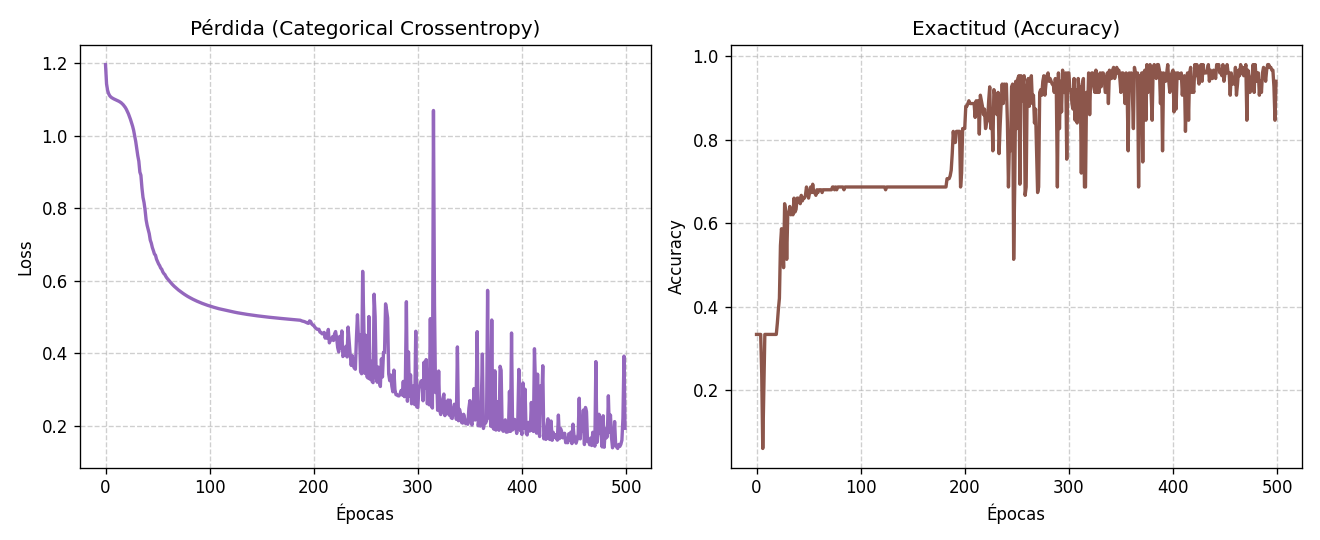

Época 500/500 - Pérdida final: 0.1937, Exactitud (Accuracy): 94.00%
Conclusión: La combinación de ReLU y Softmax evita el desvanecimiento de gradiente, permitiendo un entrenamiento fluido y alta precisión.


In [8]:
model_modern = keras.Sequential([
    layers.Dense(3, activation="relu", name="layer1", input_shape=(4,)),
    layers.Dense(3, activation="relu", name="layer2"),
    layers.Dense(3, activation="relu", name="layer3"),
    layers.Dense(3, activation="softmax", name="output")
], name="sequential_modern_relu")

optimizer = tf.keras.optimizers.SGD(learning_rate=0.03)
model_modern.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
history_modern = model_modern.fit(X, Y, epochs=500, verbose=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.plot(history_modern.history['loss'], color='#9467bd', lw=2)
ax1.set_title('Pérdida (Categorical Crossentropy)')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(history_modern.history['accuracy'], color='#8c564b', lw=2)
ax2.set_title('Exactitud (Accuracy)')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Accuracy')
ax2.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()